# 1. Codes from polynomials, and belief propagation step by step

Three codes are built from two polynomials each: the toric code, the $[[72,12,6]]$ code and the gross code $[[144,12,12]]$.
Then our own belief propagation (BP) runs on them, and every iteration is drawn.

Noise here is the simplest kind: only data qubits get $X$ errors, and checks are read perfectly.

Sources: Bravyi et al., Nature 627, 778 (2024), arXiv:2308.07915. Roffe et al., arXiv:2005.07016. Poulin & Chung, QIC 8, 987 (2008).
Panteleev & Kalachev, Quantum 5, 585 (2021).

## Setup

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))     # make the repo's qdec package importable

import numpy as np
import matplotlib.pyplot as plt
from qdec.codes import toric_code, bb72, gross_code, poly_str
from qdec.tanner import draw_tanner_torus, draw_check_support, central_check, edge_lengths, draw_qubit_set
from qdec.bp import MinSumBP, logical_failure
from qdec.bp_viz import bp_frames, qubit_traces, save_bp_gif

plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(2026)                          # fixed seed: same pictures every run

## A code from two polynomials

Take a torus of $l \times m$ cells. Let $x$ shift by one cell in the first direction and $y$ in the second. A polynomial such as
$A = x^3 + y + y^2$ is then a 0/1 matrix, one "arrow" per term. The code is

$$H_X = [\,A \mid B\,], \qquad H_Z = [\,B^{\mathsf T} \mid A^{\mathsf T}\,].$$

Since $x$ and $y$ commute, $H_X H_Z^{\mathsf T} = AB + BA = 0 \pmod 2$. The checks commute for any $A$ and $B$.
The number of logical qubits is $k = n - \operatorname{rank} H_X - \operatorname{rank} H_Z$.

In [2]:
codes = [toric_code(6), bb72(), gross_code()]
for c in codes:
    print(c.summary(), "| checks commute:", c.commutes())

toric 6x6: l=6, m=6, A = 1 + x, B = 1 + y  ->  n = 72, k = 2, check weight = 4 | checks commute: True
BB [[72,12,6]]: l=6, m=6, A = x^3 + y + y^2, B = y^3 + x + x^2  ->  n = 72, k = 12, check weight = 6 | checks commute: True
gross [[144,12,12]]: l=12, m=6, A = x^3 + y + y^2, B = y^3 + x + x^2  ->  n = 144, k = 12, check weight = 6 | checks commute: True


Each row is one check; each dot is a qubit it measures.

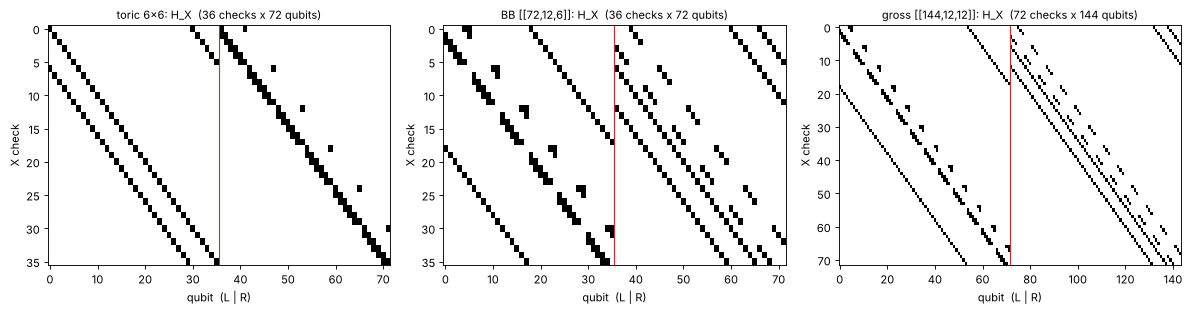

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axs, codes):
    ax.imshow(c.HX, cmap="Greys", aspect="auto", interpolation="nearest")
    ax.axvline(c.n // 2 - 0.5, c="tab:red", lw=1)
    ax.set_title(f"{c.name}: H_X  ({c.HX.shape[0]} checks x {c.n} qubits)", fontsize=10)
    ax.set_xlabel("qubit  (L | R)"); ax.set_ylabel("X check")
plt.tight_layout(); plt.show()

### Logical operators

An $X$ logical passes every $Z$ check but is not a product of $X$ checks. We find them with mod-2 linear algebra (`qdec/gf2.py`).
One is drawn below for each code. They are valid, but not always the shortest.

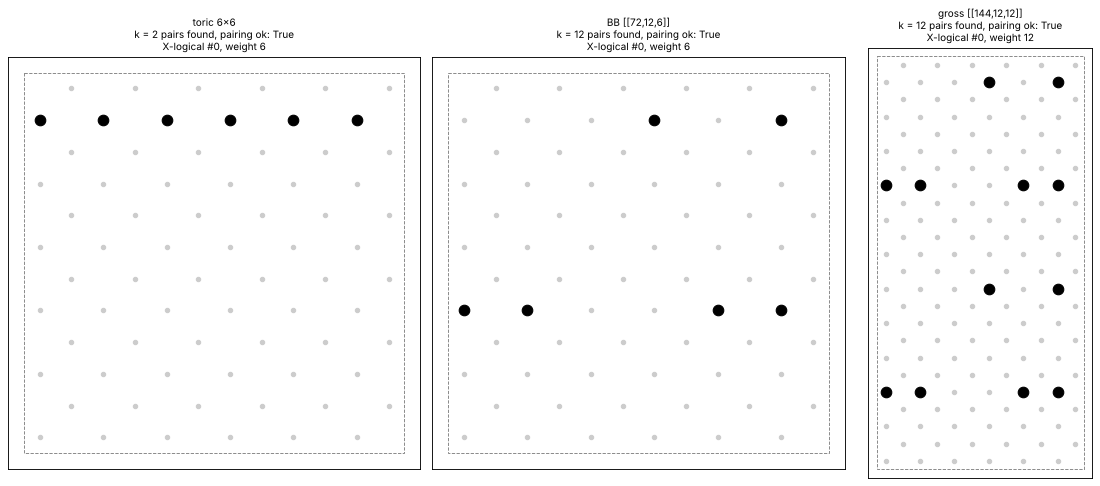

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1, 0.6]})
for ax, c in zip(axs, codes):
    LX, LZ = c.logicals()
    pairing_ok = np.array_equal((LX.astype(int) @ LZ.T) % 2, np.eye(c.k, dtype=int))
    q = np.nonzero(LX[0])[0]
    draw_qubit_set(c, q, ax, title=f"{c.name}\nk = {c.k} pairs found, pairing ok: {pairing_ok}\nX-logical #0, weight {len(q)}")
plt.tight_layout(); plt.show()

## Tanner graphs on the torus

A decoder works on a graph: one node per qubit, one per check, and an edge wherever $H$ has a 1.

In the toric layout of Bravyi et al., the toric code has only short edges. The bivariate-bicycle codes have 4 short edges and
2 long-range edges per check.

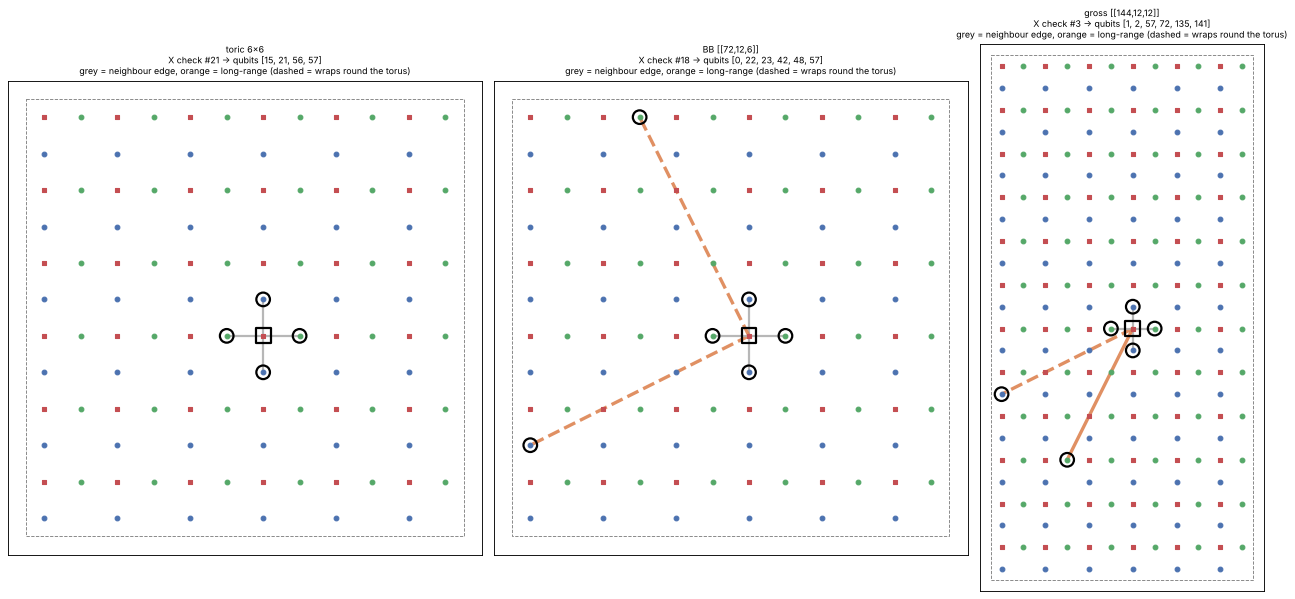

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(16, 8), gridspec_kw={"width_ratios": [1, 1, 0.6]})
for ax, c in zip(axs, codes):
    draw_check_support(c, "X", central_check(c, "X"), ax)
plt.tight_layout(); plt.show()

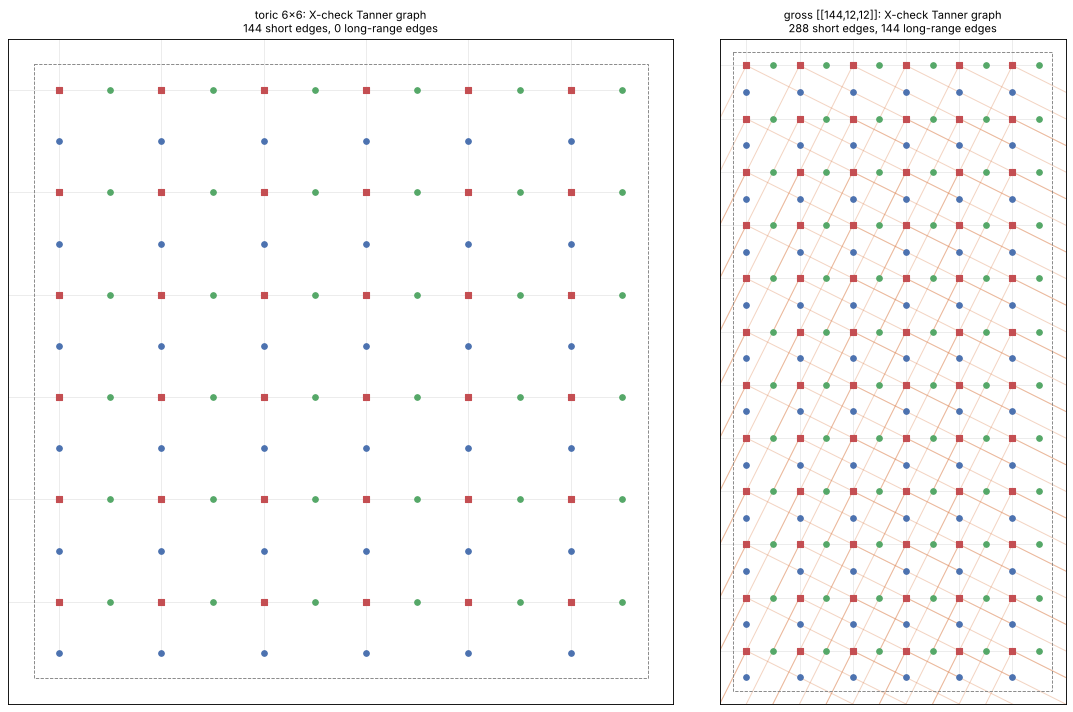

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(14, 9), gridspec_kw={"width_ratios": [1, 0.6]})
draw_tanner_torus(codes[0], "X", axs[0])
draw_tanner_torus(codes[2], "X", axs[1])
plt.tight_layout(); plt.show()

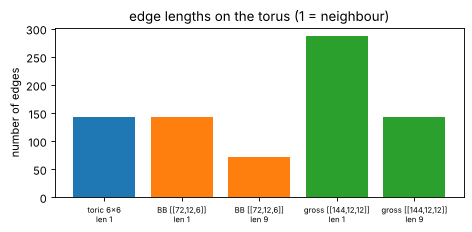

In [7]:
fig, ax = plt.subplots(figsize=(6, 3))
for c in codes:
    lens = edge_lengths(c, "X")
    vals, cnt = np.unique(lens, return_counts=True)
    ax.bar([f"{c.name}\nlen {v}" for v in vals], cnt)
ax.set_ylabel("number of edges"); ax.set_title("edge lengths on the torus (1 = neighbour)")
plt.xticks(fontsize=7); plt.tight_layout(); plt.show()

## Our belief propagation

Each qubit holds a belief $\mathrm{LLR} = \log\frac{P(\text{fine})}{P(\text{flipped})}$. Positive means "probably fine".

1. Every qubit starts at the prior $\log\frac{1-p}{p}$.
2. **Check to qubit:** the sign is $(-1)^{s}$ times the product of the other signs. The size is $\alpha$ times the smallest of the
   other messages, with $\alpha = 0.625$.
3. **Qubit belief:** the prior plus everything it heard. Negative means "flipped".
4. **Qubit to check:** its belief minus what that check just said.
5. Stop when the guess satisfies every check, or after `max_iter` rounds.

The code is in `qdec/bp.py`. Below it is compared with the `ldpc` package on random syndromes.

toric 6x6              identical corrections: 300/300
BB [[72,12,6]]         identical corrections: 300/300


gross [[144,12,12]]    identical corrections: 300/300


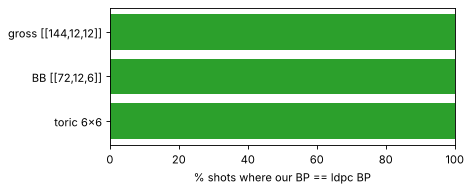

In [8]:
from ldpc import BpDecoder          # only used here, as an independent check

rows = []
for c, p in [(codes[0], 0.05), (codes[1], 0.04), (codes[2], 0.04)]:
    H = c.HZ                           # X errors are seen by the Z checks
    ours = MinSumBP(H, p, max_iter=30, alpha=0.625)
    lib = BpDecoder(H, error_rate=p, max_iter=30, bp_method="minimum_sum",
                    ms_scaling_factor=0.625, schedule="parallel")
    same, N = 0, 300
    for _ in range(N):
        e = (rng.random(c.n) < p).astype(np.uint8)
        s = (H.astype(int) @ e) % 2
        same += np.array_equal(ours.decode(s).correction, lib.decode(s))
    rows.append((c.name, same, N))
    print(f"{c.name:22s} identical corrections: {same}/{N}")

fig, ax = plt.subplots(figsize=(6, 2.5))
ax.barh([r[0] for r in rows], [100 * r[1] / r[2] for r in rows], color="tab:green")
ax.set_xlim(0, 100); ax.set_xlabel("% shots where our BP == ldpc BP"); plt.tight_layout(); plt.show()

## BP succeeds (gross code)

A random weight-4 error. Gold: lit checks. Colour: BP's chance that the qubit flipped. Cross: the true error. Ring: BP's guess.

iterations: 3 | unsatisfied per iteration: [10  3  4  0] | logical error after correction: False


'figs/gross_bp_success.gif'

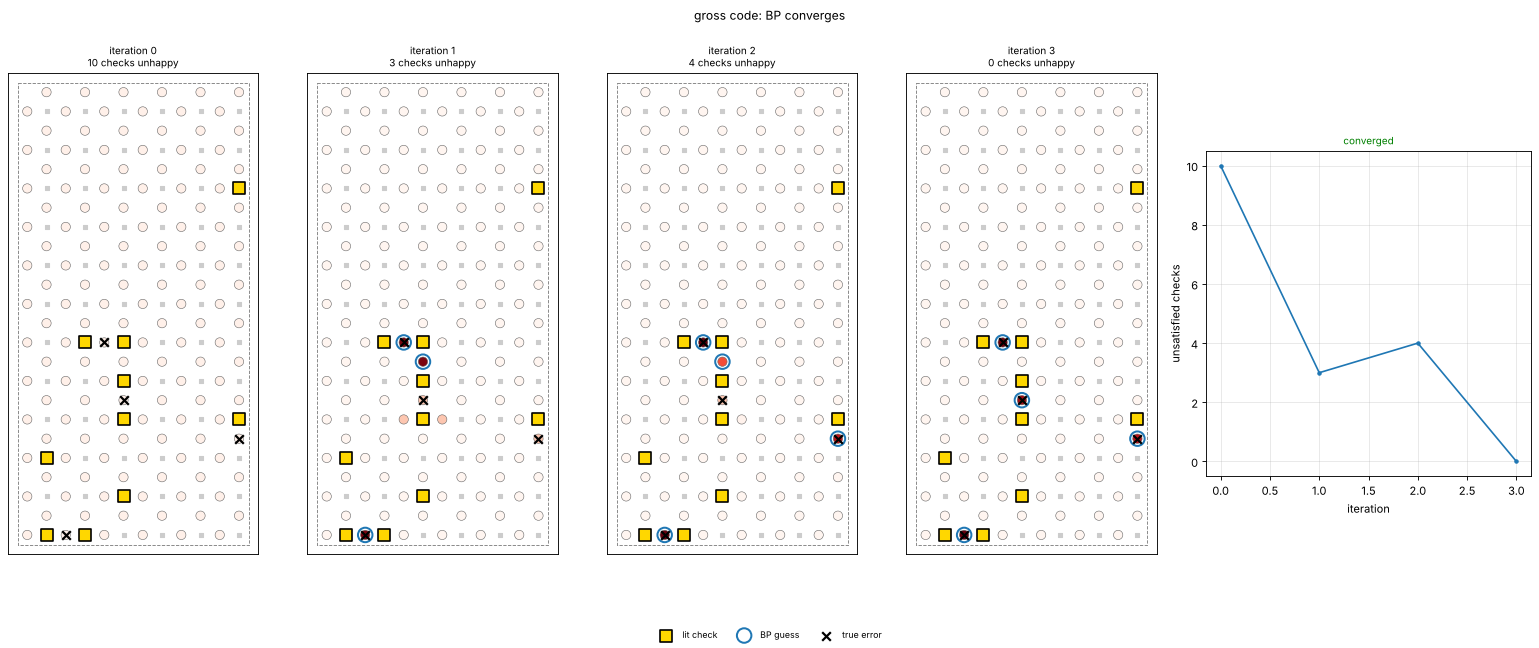

In [9]:
g = codes[2]
H = g.HZ.astype(int)
bp = MinSumBP(H, error_rate=0.03, max_iter=50)

while True:                                            # find a case that needs a few iterations
    e = np.zeros(g.n, dtype=int); e[rng.choice(g.n, 4, replace=False)] = 1
    s = (H @ e) % 2
    res = bp.decode(s)
    if res.converged and res.iterations >= 3:
        break
LX, LZ = g.logicals()
print("iterations:", res.iterations, "| unsatisfied per iteration:", res.unsatisfied_history,
      "| logical error after correction:", logical_failure(e, res.correction, LZ))
bp_frames(g, "Z", res, s, e, suptitle="gross code: BP converges").show()
save_bp_gif(g, "Z", res, s, e, "figs/gross_bp_success.gif")

## Failure 1: a tie (toric code)

Two lit checks sit diagonally. Two corrections are equally short, and either would work. BP cannot break the tie: all four qubits
get the same probability, below one half, so its guess never satisfies the checks (Poulin & Chung, 2008).

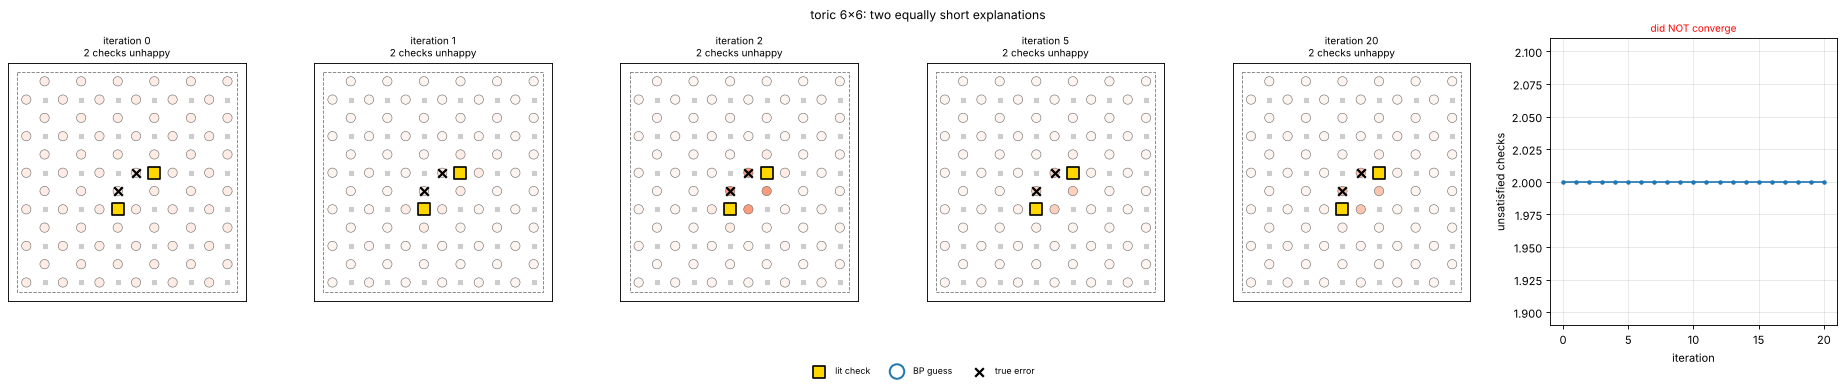

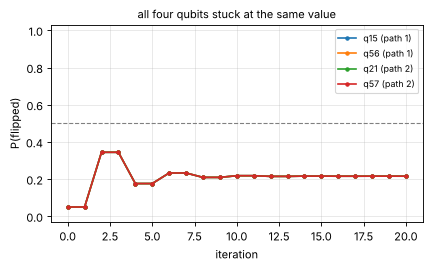

In [10]:
t = codes[0]
Ht = t.HZ.astype(int)
e = np.zeros(t.n, dtype=int); e[[15, 56]] = 1               # one of the two shortest explanations
s = (Ht @ e) % 2
res = MinSumBP(Ht, error_rate=0.05, max_iter=20).decode(s)
bp_frames(t, "Z", res, s, e, iterations=[0, 1, 2, 5, 20], suptitle="toric 6x6: two equally short explanations").show()
qubit_traces(res, [15, 56, 21, 57], labels=["q15 (path 1)", "q56 (path 1)", "q21 (path 2)", "q57 (path 2)"],
             title="all four qubits stuck at the same value")
plt.show()

In [11]:
# How common is this? Every 2-lit-check syndrome on the 6x6 toric code that has two weight-2 explanations:
import itertools
from collections import defaultdict
by_syndrome = defaultdict(list)
for a, b in itertools.combinations(range(t.n), 2):
    e = np.zeros(t.n, dtype=int); e[[a, b]] = 1
    s = tuple((Ht @ e) % 2)
    if sum(s) == 2:
        by_syndrome[s].append((a, b))
tied = [s for s, v in by_syndrome.items() if len(v) >= 2]
bp_t = MinSumBP(Ht, 0.05, max_iter=40)
ok = sum(bp_t.decode(np.array(s)).converged for s in tied)
print(f"{len(tied)} tied syndromes, BP converged on {ok} of them")

72 tied syndromes, BP converged on 0 of them


## Failure 2: oscillation (gross code)

The gross code has distance 12, so every weight-4 error is correctable in principle. BP still sometimes never settles. Short loops
in the Tanner graph feed messages back to where they started. This is why the gross code is decoded with BP plus a second stage.

unsatisfied checks per iteration: [12  9  9  9  9  9  9  9  9  9 12  9  9  9  9  9  9  9  9  9  9  9  9  9
  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9
  9  9  9]


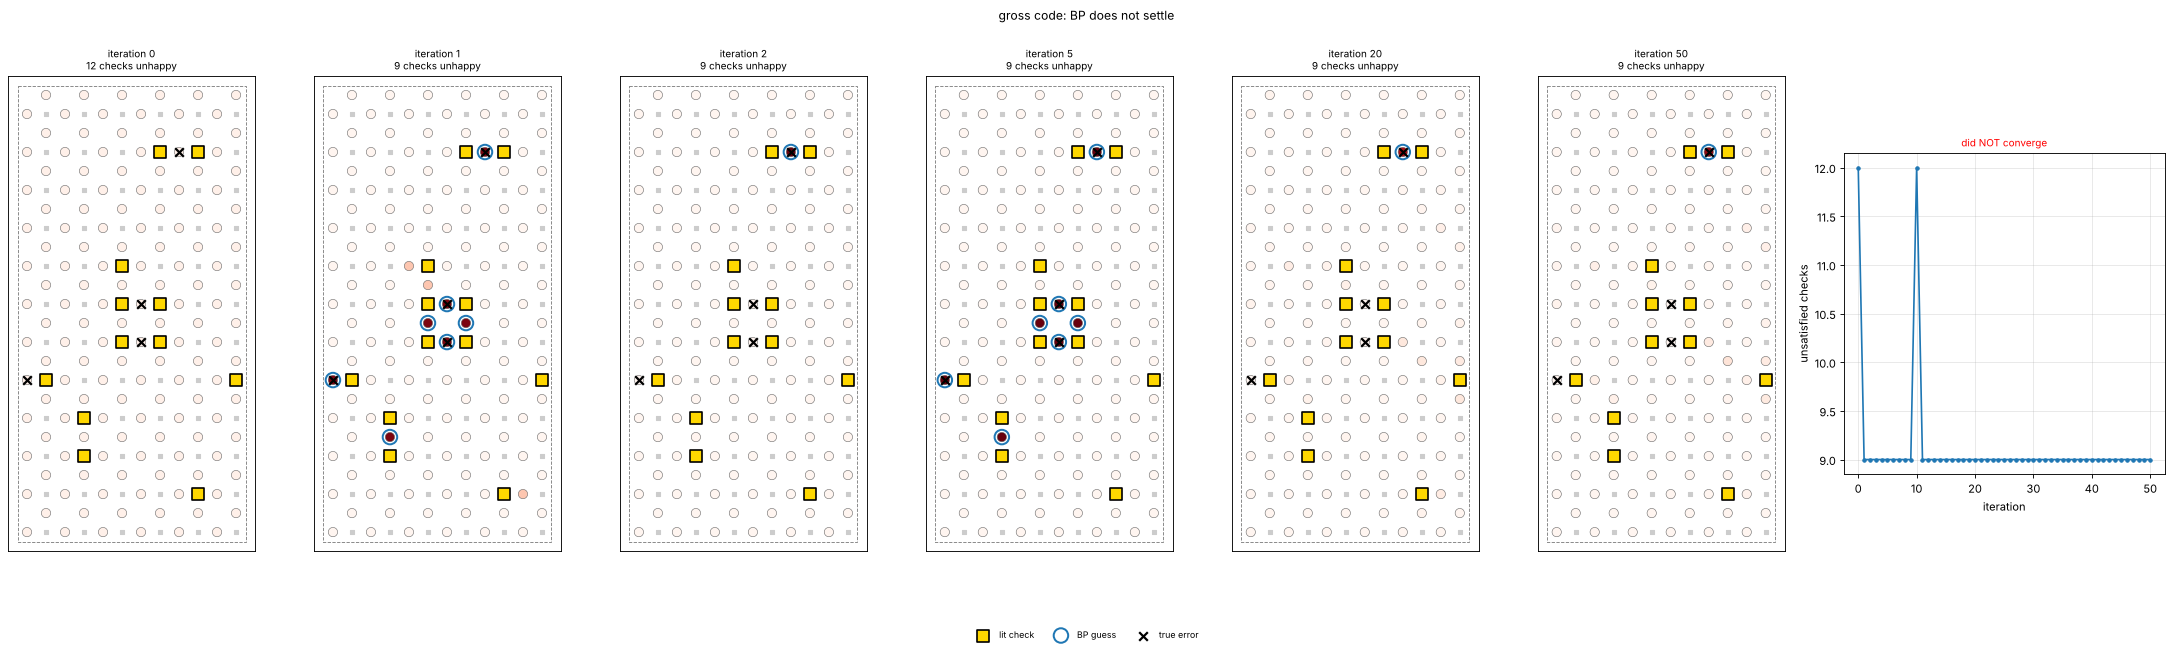

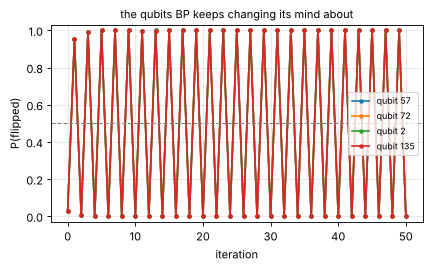

'figs/gross_bp_fail.gif'

In [12]:
while True:
    e = np.zeros(g.n, dtype=int); e[rng.choice(g.n, 4, replace=False)] = 1
    s = (H @ e) % 2
    res = bp.decode(s)
    if not res.converged:
        break
print("unsatisfied checks per iteration:", res.unsatisfied_history)
bp_frames(g, "Z", res, s, e, iterations=[0, 1, 2, 5, 20, 50], suptitle="gross code: BP does not settle").show()

# the qubits whose probability swings the most over the last 20 iterations
top = np.argsort(-res.prob_history[-20:].std(0))[:4]
qubit_traces(res, top, title="the qubits BP keeps changing its mind about"); plt.show()
save_bp_gif(g, "Z", res, s, e, "figs/gross_bp_fail.gif")

## How often does BP fail?

A shot fails if BP does not converge, or converges to a logical error. The same shots also go to `ldpc`'s BP + OSD for comparison.

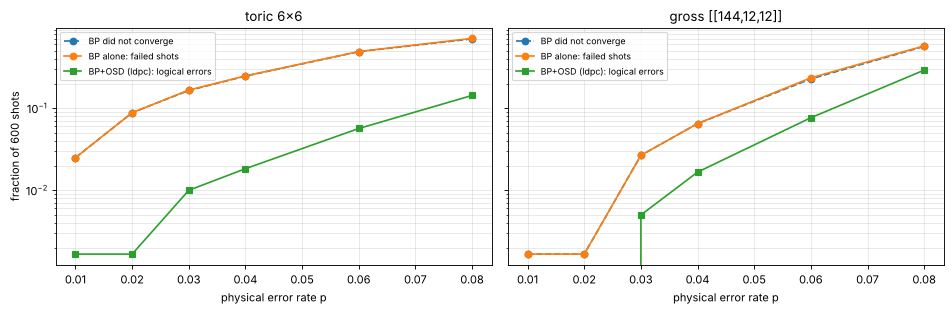

In [13]:
from ldpc import BpOsdDecoder

ps = [0.01, 0.02, 0.03, 0.04, 0.06, 0.08]
shots = 600
results = {}
for c in [codes[0], codes[2]]:
    Hc = c.HZ.astype(int); LXc, LZc = c.logicals()
    nonconv, fail_bp, fail_osd = [], [], []
    for p in ps:
        ours = MinSumBP(Hc, p, max_iter=50)
        osd = BpOsdDecoder(c.HZ, error_rate=p, max_iter=50, bp_method="minimum_sum",
                           ms_scaling_factor=0.625, osd_method="osd_cs", osd_order=7)
        nc = fb = fo = 0
        for _ in range(shots):
            e = (rng.random(c.n) < p).astype(int)
            s = (Hc @ e) % 2
            r = ours.decode(s)
            nc += not r.converged
            fb += (not r.converged) or logical_failure(e, r.correction, LZc)
            fo += logical_failure(e, osd.decode(s.astype(np.uint8)), LZc)
        nonconv.append(nc / shots); fail_bp.append(fb / shots); fail_osd.append(fo / shots)
    results[c.name] = (nonconv, fail_bp, fail_osd)

fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, (nc, fb, fo)) in zip(axs, results.items()):
    ax.plot(ps, nc, "o--", label="BP did not converge")
    ax.plot(ps, fb, "o-", label="BP alone: failed shots")
    ax.plot(ps, fo, "s-", label="BP+OSD (ldpc): logical errors")
    ax.set_yscale("log"); ax.set_xlabel("physical error rate p"); ax.set_title(name)
    ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
axs[0].set_ylabel(f"fraction of {shots} shots")
plt.tight_layout(); plt.show()

## Summary

- Two polynomials give the whole code. The checks commute, and $n$ and $k$ match the papers.
- The toric code has only neighbour edges. Bivariate-bicycle codes add 2 long edges per check.
- Our BP gives the same answers as `ldpc`. It fails in two ways: it freezes on ties, and it oscillates on the gross code.

Next: notebook 2 draws every code in the catalogue.